# Prédiction du nombre de locations de vélos avec un perceptron multicouche

## 0. Imports

In [4]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

## 1. Chargement et prétraitement

In [5]:
df = pd.read_csv("data/day.csv")
print(df.shape, "| valeurs manquantes :", df.isna().sum().sum())

print("Corrélation temp / atemp :", round(df["temp"].corr(df["atemp"]), 3))
print("Corrélation registered / cnt :", round(df["registered"].corr(df["cnt"]), 3))

df = df.drop(columns=["instant", "dteday", "casual", "registered", "atemp"])

(731, 16) | valeurs manquantes : 0
Corrélation temp / atemp : 0.992
Corrélation registered / cnt : 0.946


In [6]:
df = pd.get_dummies(df, columns=["season", "mnth", "weekday", "weathersit"], dtype="float")

X = df.drop(columns=["cnt"]).values
y = df["cnt"].values.reshape(-1, 1)
print("X :", X.shape, "| y :", y.shape)

X : (731, 32) | y : (731, 1)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train = scaler_y.fit_transform(y_train)
y_test = scaler_y.transform(y_test)

ECART_TYPE = scaler_y.scale_[0]
reel = scaler_y.inverse_transform(y_test)

print(f"Entraînement : {X_train.shape[0]} jours | Test : {X_test.shape[0]} jours")

Entraînement : 584 jours | Test : 147 jours


## 2. Référence naïve

In [8]:
moyenne_train = scaler_y.inverse_transform(y_train).mean()
mae_naive = np.mean(np.abs(reel - moyenne_train))
print(f"Prédiction naïve ({moyenne_train:.0f} vélos tous les jours) : MAE test = {mae_naive:.0f} vélos")

Prédiction naïve (4561 vélos tous les jours) : MAE test = 1712 vélos


## 3. Fonctions

In [9]:
def construire_modele(neurones=100, dropout=0.0, l2=0.0, learning_rate=0.001):
    model = keras.Sequential()
    model.add(keras.Input(shape=(X_train.shape[1],)))
    for _ in range(2):
        model.add(layers.Dense(neurones, activation="relu",
                               kernel_regularizer=regularizers.l2(l2)))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="linear"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="mse", metrics=["mae"])
    return model

def entrainer(params, batch_size=32, epochs=50, callbacks=None, graine=42):
    keras.utils.set_random_seed(graine)
    model = construire_modele(**params)
    h = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                  validation_split=0.2, callbacks=callbacks or [], verbose=0)
    return model, h

def mae_val_velos(h):
    return min(h.history["val_mae"]) * ECART_TYPE

def mae_test_velos(model):
    pred = scaler_y.inverse_transform(model.predict(X_test, verbose=0))
    return np.mean(np.abs(pred - reel))

arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                      restore_best_weights=True)

## 4. Modèle de départ

MAE validation : 576 vélos


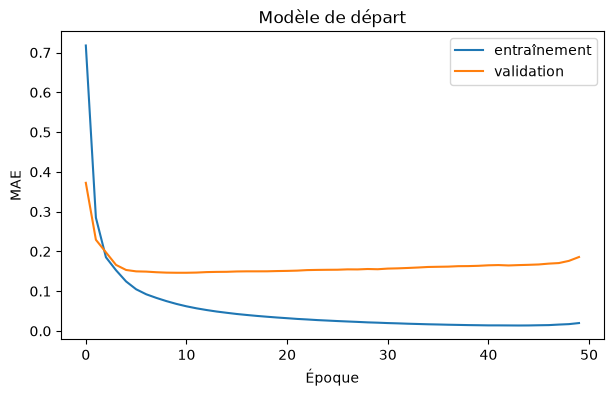

In [23]:
model_base, h_base = entrainer({}, batch_size=32, epochs=50)

print(f"MAE validation : {mae_val_velos(h_base):.0f} vélos")

plt.figure(figsize=(7, 4))
plt.plot(h_base.history["loss"], label="entraînement")
plt.plot(h_base.history["val_loss"], label="validation")
plt.title("Modèle de départ")
plt.xlabel("Époque")
plt.ylabel("MAE"); plt.legend(); plt.show()

## 5. Recherche d'hyperparamètres

In [11]:
def tester(nom, valeurs, epochs=50):
    scores = {}
    plt.figure(figsize=(7, 4))
    for v in valeurs:
        if nom == "batch_size":
            _, h = entrainer({}, batch_size=v, epochs=epochs)
        else:
            _, h = entrainer({nom: v}, epochs=epochs)
        scores[v] = mae_val_velos(h)
        print(f"{nom} = {v} : MAE validation = {scores[v]:.0f} vélos")
        plt.plot(h.history["val_loss"], label=f"{nom}={v}")
    plt.title(f"Effet de {nom}")
    plt.xlabel("Époque"); plt.ylabel("MSE (validation)"); plt.legend(); plt.show()
    meilleur = min(scores, key=scores.get)
    print("→ meilleure valeur :", meilleur)
    return meilleur

neurones = 8 : MAE validation = 653 vélos
neurones = 32 : MAE validation = 621 vélos
neurones = 100 : MAE validation = 576 vélos
neurones = 256 : MAE validation = 558 vélos


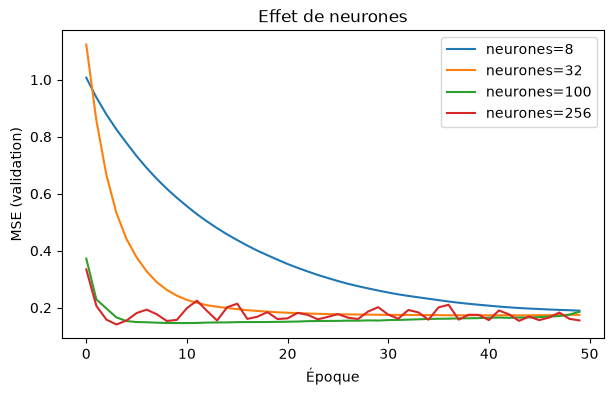

→ meilleure valeur : 256


In [12]:
best_neurones = tester("neurones", [8, 32, 100, 256])

dropout = 0.0 : MAE validation = 576 vélos
dropout = 0.1 : MAE validation = 542 vélos
dropout = 0.3 : MAE validation = 554 vélos
dropout = 0.5 : MAE validation = 696 vélos


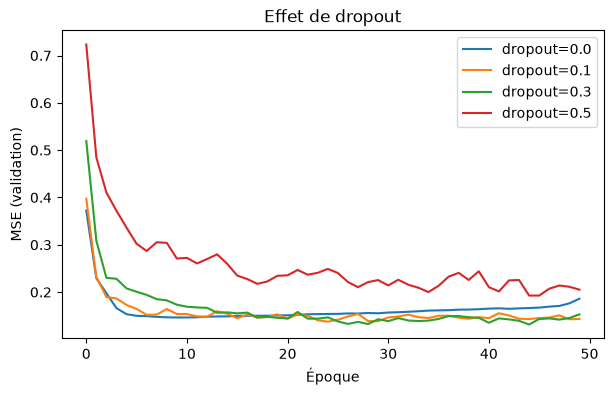

→ meilleure valeur : 0.1


In [13]:
best_dropout = tester("dropout", [0.0, 0.1, 0.3, 0.5])

l2 = 0.0 : MAE validation = 576 vélos
l2 = 0.0001 : MAE validation = 576 vélos
l2 = 0.001 : MAE validation = 556 vélos
l2 = 0.01 : MAE validation = 512 vélos


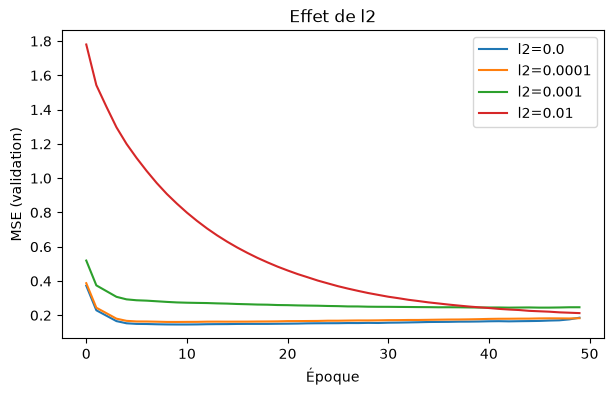

→ meilleure valeur : 0.01


In [14]:
best_l2 = tester("l2", [0.0, 0.0001, 0.001, 0.01])

learning_rate = 0.0001 : MAE validation = 628 vélos
learning_rate = 0.001 : MAE validation = 576 vélos
learning_rate = 0.01 : MAE validation = 528 vélos
learning_rate = 0.05 : MAE validation = 623 vélos


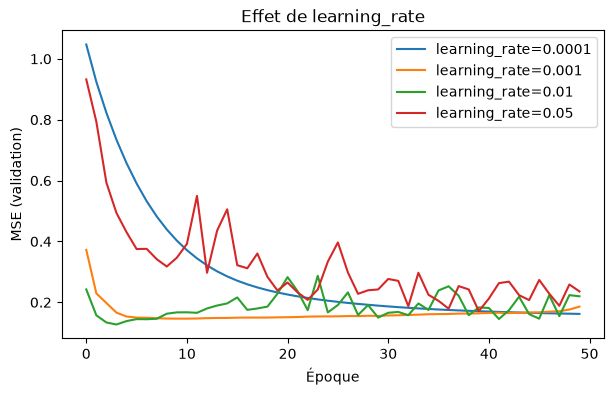

→ meilleure valeur : 0.01


In [15]:
best_lr = tester("learning_rate", [0.0001, 0.001, 0.01, 0.05])

batch_size = 16 : MAE validation = 568 vélos
batch_size = 32 : MAE validation = 576 vélos
batch_size = 128 : MAE validation = 591 vélos


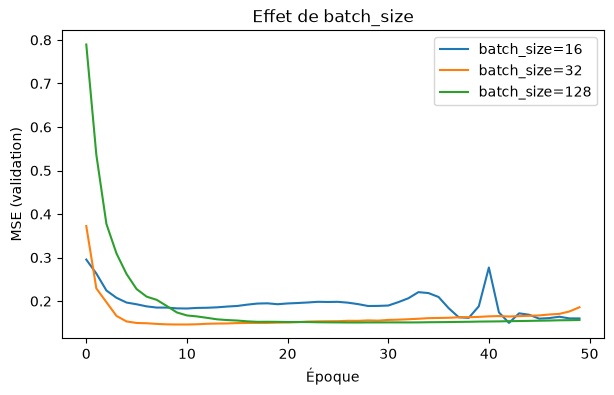

→ meilleure valeur : 16


In [16]:
best_batch = tester("batch_size", [16, 32, 128])

## 6. Comparaison des combinaisons

In [17]:
def evaluer(params, batch_size, graines=(0, 1, 2, 3, 4)):
    vals, tests = [], []
    for g in graines:
        model, h = entrainer(params, batch_size=batch_size, epochs=300,
                             callbacks=[arret], graine=g)
        vals.append(mae_val_velos(h))
        tests.append(mae_test_velos(model))
    return np.mean(vals), np.std(vals), np.mean(tests), np.std(tests)

meilleurs = dict(neurones=best_neurones, dropout=best_dropout, l2=best_l2, learning_rate=best_lr)

combinaisons = {
    "Départ":                ({}, 32),
    "Meilleurs individuels": (meilleurs, best_batch),
    "Variante A (batch 32)": (meilleurs, 32),
    "Variante B (lr 0.001)": ({**meilleurs, "learning_rate": 0.001}, best_batch),
}

lignes = []
for nom, (params, bs) in combinaisons.items():
    mv, sv, mt, st = evaluer(params, bs)
    lignes.append({"combinaison": nom, "paramètres": {**params, "batch_size": bs},
                   "MAE val": f"{mv:.0f} ± {sv:.0f}", "MAE test": f"{mt:.0f} ± {st:.0f}",
                   "_val": mv})
    print(f"{nom:<24} validation {mv:.0f} ± {sv:.0f} | test {mt:.0f} ± {st:.0f}")

resultats = pd.DataFrame(lignes).sort_values("_val")
resultats.drop(columns="_val").reset_index(drop=True)

Départ                   validation 598 ± 24 | test 573 ± 26
Meilleurs individuels    validation 525 ± 15 | test 564 ± 27
Variante A (batch 32)    validation 518 ± 31 | test 541 ± 39
Variante B (lr 0.001)    validation 476 ± 17 | test 492 ± 21


,combinaison,paramètres,MAE val,MAE test
0,Variante B (lr 0.001),"{'neurones': 256, 'dropout': 0.1, 'l2': 0.01, ...",476 ± 17,492 ± 21
1,Variante A (batch 32),"{'neurones': 256, 'dropout': 0.1, 'l2': 0.01, ...",518 ± 31,541 ± 39
2,Meilleurs individuels,"{'neurones': 256, 'dropout': 0.1, 'l2': 0.01, ...",525 ± 15,564 ± 27
3,Départ,{'batch_size': 32},598 ± 24,573 ± 26


In [18]:
nom_final = resultats.iloc[0]["combinaison"]
params_final, batch_final = combinaisons[nom_final]
print("Combinaison retenue :", nom_final)
print("Paramètres :", {**params_final, "batch_size": batch_final})

Combinaison retenue : Variante B (lr 0.001)
Paramètres : {'neurones': 256, 'dropout': 0.1, 'l2': 0.01, 'learning_rate': 0.001, 'batch_size': 16}


## 7. Modèle final

In [19]:
model_final, h_final = entrainer(params_final, batch_size=batch_final, epochs=300,
                                 callbacks=[arret], graine=42)

meilleure_epoque = int(np.argmin(h_final.history["val_loss"])) + 1
pred = scaler_y.inverse_transform(model_final.predict(X_test, verbose=0))
erreurs = pred - reel
mae_finale = np.mean(np.abs(erreurs))

print(f"Meilleure époque : {meilleure_epoque} (sur {len(h_final.history['val_loss'])} jouées)")
print(f"MAE test : {mae_finale:.0f} vélos")

Meilleure époque : 61 (sur 71 jouées)
MAE test : 504 vélos


## 8. Bilan

In [21]:
mae_depart = mae_test_velos(model_base)
moyenne_jour = reel.mean()

bilan = pd.DataFrame({
    "modèle": ["Prédiction naïve (moyenne)", "Modèle de départ", f"Modèle final ({nom_final})"],
    "MAE test (vélos)": [round(mae_naive), round(mae_depart), round(mae_finale)],
    "% de la moyenne journalière": [f"{100*m/moyenne_jour:.0f} %" for m in (mae_naive, mae_depart, mae_finale)],
})
bilan

,modèle,MAE test (vélos),% de la moyenne journalière
0,Prédiction naïve (moyenne),1712,40 %
1,Modèle de départ,584,14 %
2,Modèle final (Variante B (lr 0.001)),504,12 %
